<h1 align='center'>Experiment - 2</h1>
<h3 align='center'>To implement operations on individual image pixels</h3>

Name: Sumeet Sambhaji Bhosale \
Roll No: 4163 \
Class: B.Tech-B (B8) \
URN: 23031024

---

In [1]:
import cv2

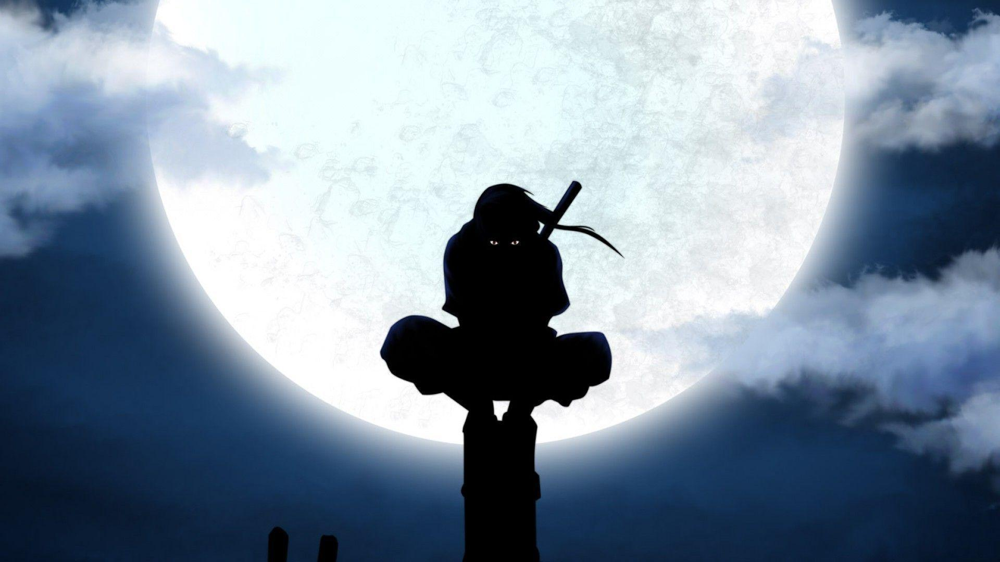

In [26]:
from IPython.display import Image
Image('Itachi.jpg')

---

1. Read Specific Pixel Value

In [18]:
src = cv2.imread('Itachi.jpg')
src.size

6220800

In [19]:
src.shape

(1080, 1920, 3)

In [20]:
print(f"Height: {src.shape[0]}, Width: {src.shape[1]}, Color Channel: {src.shape[-1]}")

Height: 1080, Width: 1920, Color Channel: 3


In [23]:
print(src[550, 200])
print(src[550, 200, 0])
print(src[550, 200, 1])
print(src[550, 200, 2])


[86 49 21]
86
49
21


---

2. Display different R, G, B Channels

**Red Channel**

In [24]:
src[:, :, :2] = 0
cv2.imshow('RedImage', src)
cv2.waitKey(0)
cv2.destroyAllWindows()

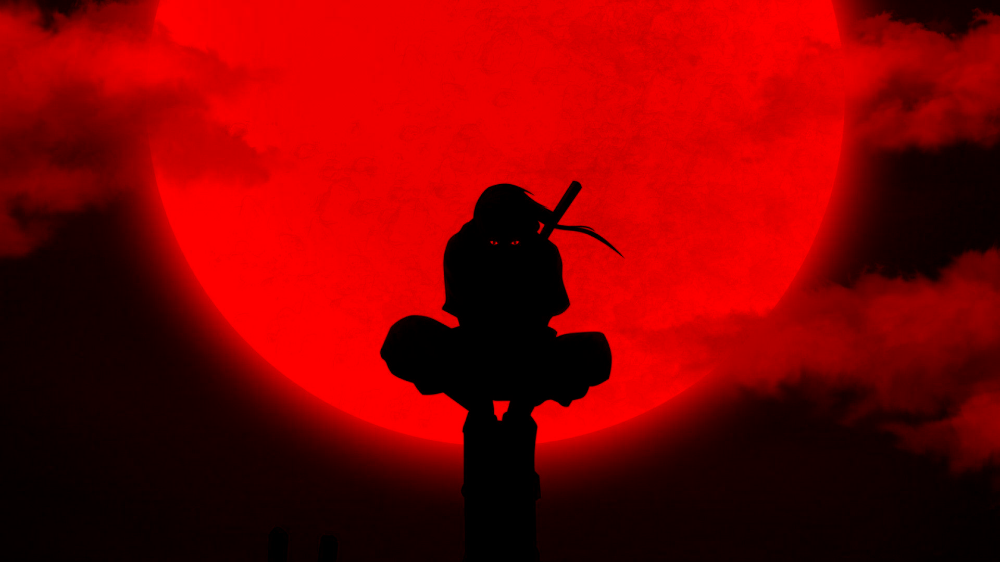

In [29]:
from IPython.display import display
from PIL import Image

src_rgb = cv2.cvtColor(src, cv2.COLOR_BGR2RGB)
display(Image.fromarray(src_rgb))

**Blue Channel**

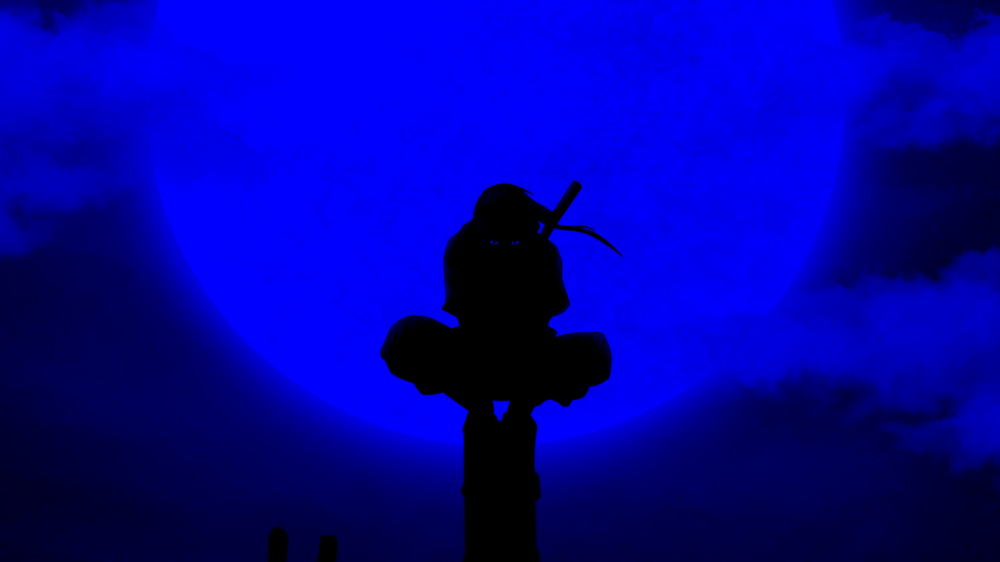

In [30]:
src = cv2.imread('Itachi.jpg')
src[:, :, 1:] = 0
display(Image.fromarray(cv2.cvtColor(src, cv2.COLOR_BGR2RGB)))

**Green Channel**

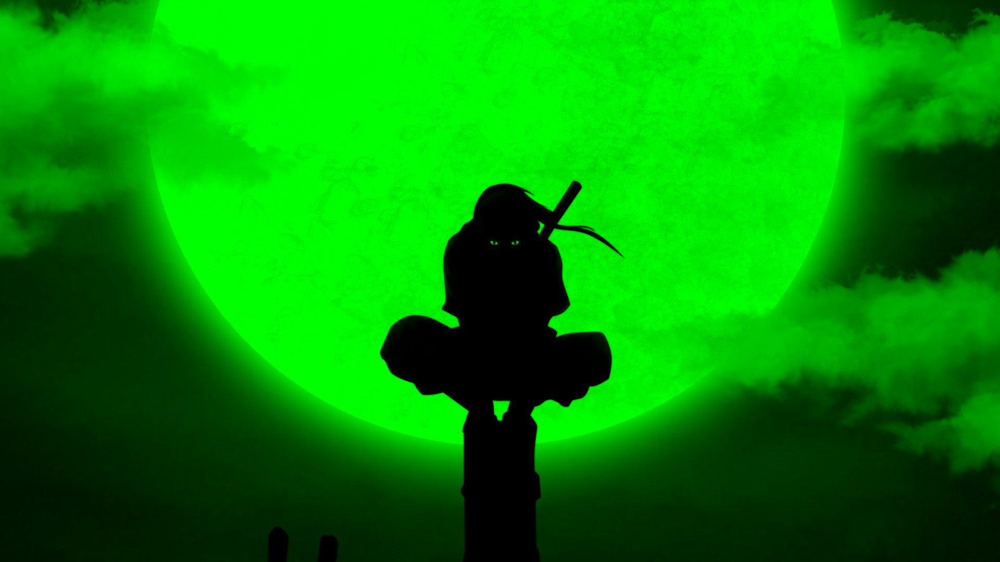

In [31]:
src = cv2.imread('Itachi.jpg')
src[:, :, [0, 2]] = 0
display(Image.fromarray(cv2.cvtColor(src, cv2.COLOR_BGR2RGB)))

---

3. Convert Image in different color spaces

- Negative Image

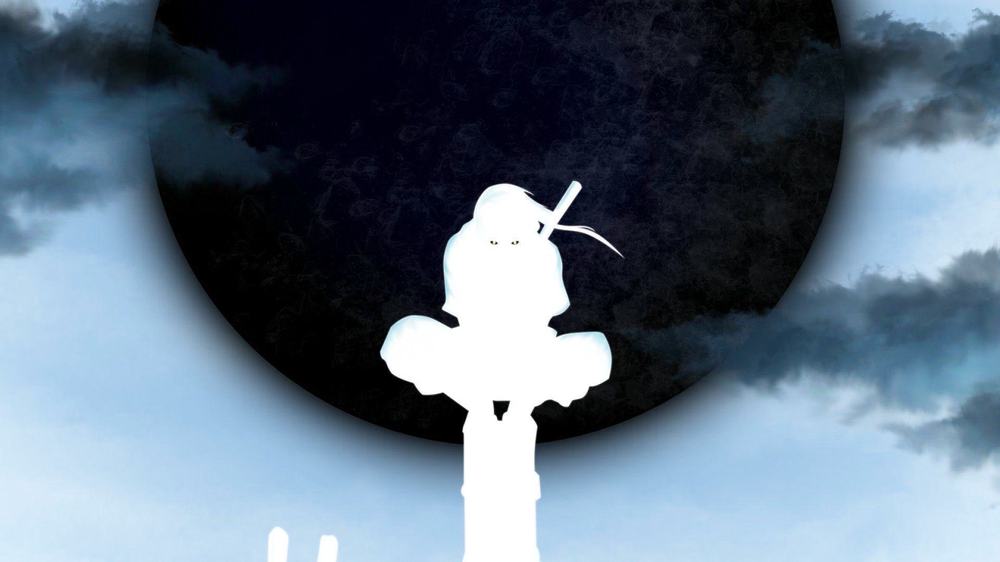

In [32]:
src = cv2.imread('Itachi.jpg')
display(Image.fromarray(src.max() - src))

- Gray Image

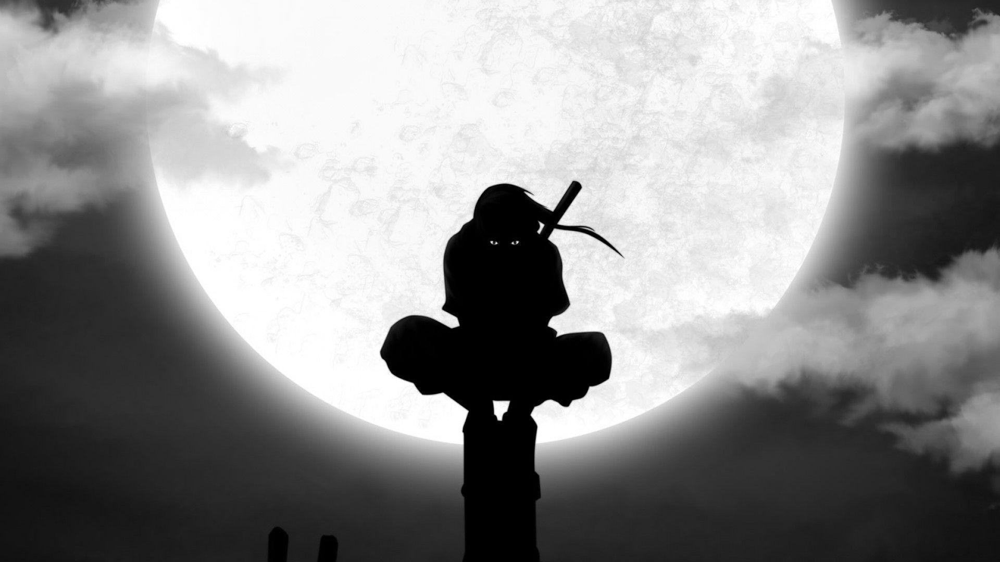

In [33]:
display(Image.fromarray(cv2.cvtColor(src, cv2.COLOR_BGR2GRAY)))

- HSV Image

An HSV Image is an image represented in the HSV color space (Hue, Saturation, Value) rather than the standard RGB (Red, Green, Blue) or BGR format.  It reorganizes color information to align more closely with human perception of color, making it highly effective for computer vision tasks like color segmentation and object tracking

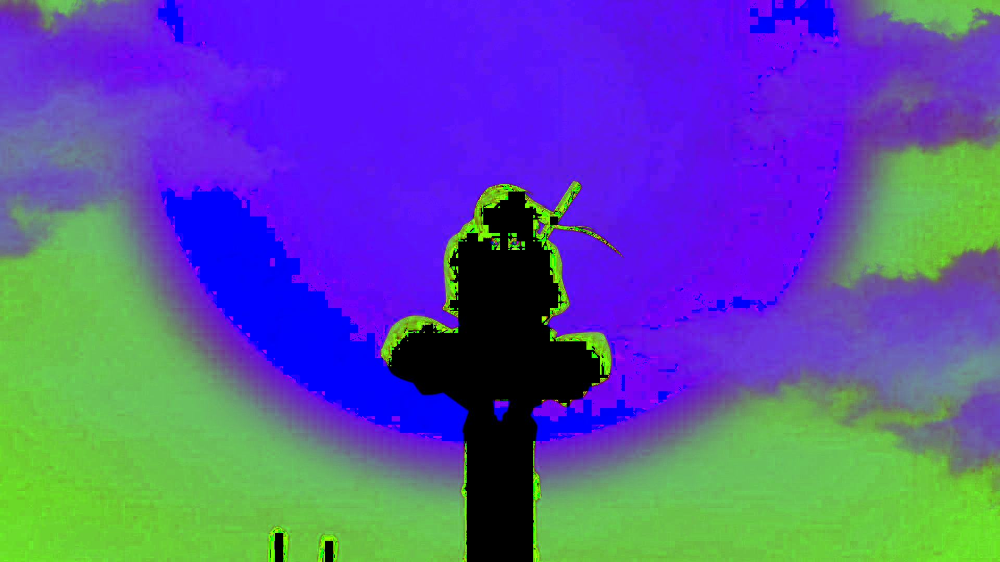

In [34]:
display(Image.fromarray(cv2.cvtColor(src, cv2.COLOR_BGR2HSV)))

- YCBCR Image

A YCrCb Image is an image represented in the YCrCb color space (also known as YCbCr), which separates an image into Luma (brightness) and Chroma (color difference) components.  Like HSV, it is designed to align with human visual perception, but it is primarily used for digital video compression and transmission (e.g., JPEG, MPEG) rather than color segmentation

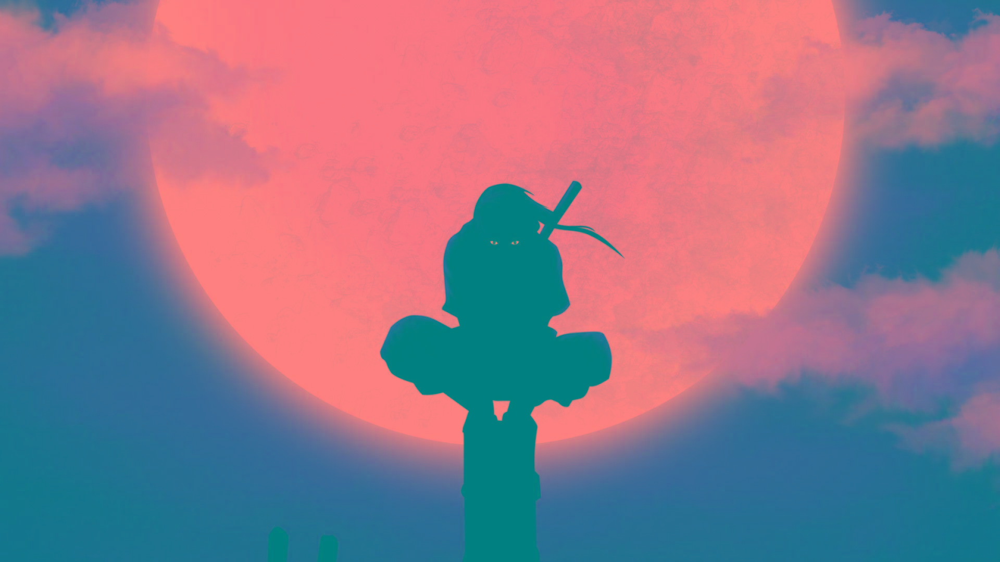

In [35]:
display(Image.fromarray(cv2.cvtColor(src, cv2.COLOR_BGR2YCR_CB)))

Increase the brightness of an image by 50 units and display the result.

In [36]:
import numpy as np
import matplotlib.pyplot as plt

In [37]:
src = cv2.imread('Itachi.jpg')

In [38]:
hsv = cv2.cvtColor(src, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)

In [39]:
v_increased = cv2.add(v, 50)

In [40]:
hsv_increased = cv2.merge([h, s, v_increased])

In [41]:
brightened_src = cv2.cvtColor(hsv_increased, cv2.COLOR_HSV2BGR)

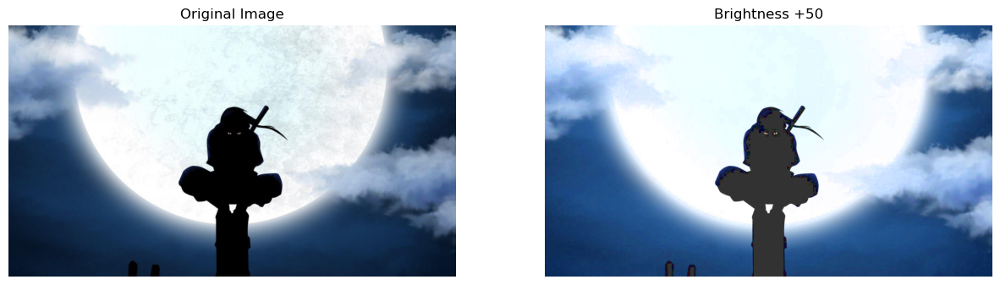

In [42]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(src, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Brightness +50")
plt.imshow(cv2.cvtColor(brightened_src, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

---

Apply binary thresholding with a threshold value of 127.

In [43]:
src = cv2.imread('Itachi.jpg', 0)

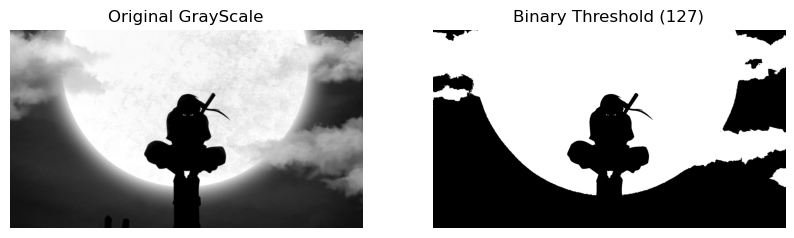

In [44]:
_, binary_img = cv2.threshold(src, 127, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.title("Original GrayScale")
plt.imshow(src, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Binary Threshold (127)")
plt.imshow(binary_img, cmap='gray')
plt.axis('off')

plt.show()

The function `cv2.threshold()` returns two values:
- `retval` (ignored here with `_`): Threshold value used
- `dst` (`binary_img`): The resulting thresholded image

---

Perform contrast stretching on an input image using min-max normalization.

To perform contrast stretching using min-max normalization, you map the current pixel intensity range [min,max] to full dynamic range [0,255]. This enhances the image by spreading out the most frequent intensity values.

The Formula

For every pixel $P$ in the image: $P_{new} = \frac{P - P_{min}}{P_{max}-P_{min}} \times 255$

In [45]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [71]:
src = cv2.imread('1322308.jpeg', 0)

In [72]:
min_val = np.min(src)
max_val = np.max(src)

In [73]:
if max_val > min_val:
    stretched = ((src - min_val) / (max_val - min_val) * 255).astype(np.uint8)
else:
    stretched = src

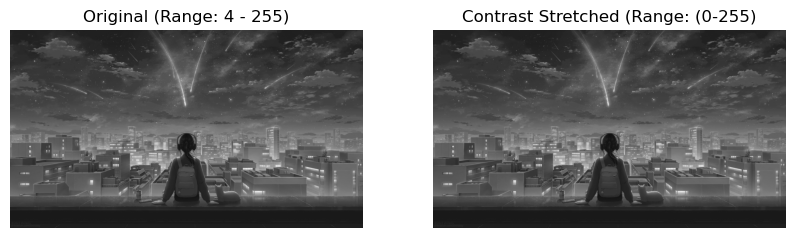

In [74]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title(f"Original (Range: {min_val} - {max_val})")
plt.imshow(src, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Contrast Stretched (Range: (0-255)")
plt.imshow(stretched, cmap='gray')
plt.axis('off')

plt.show()

---

 Compare original and negative images using matplotlib.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
img = cv2.imread('image.jpg')
original_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

negative_rgb = 255 - original_rgb

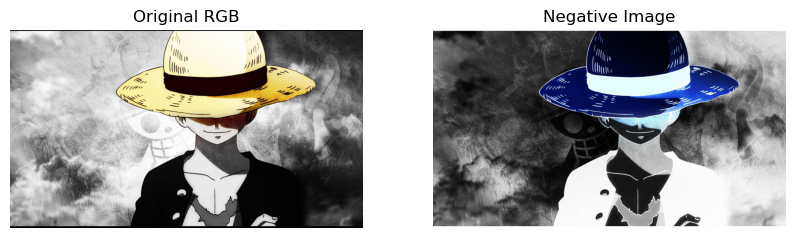

In [3]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title('Original RGB')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(negative_rgb)
plt.title('Negative Image')
plt.axis('off')

plt.show()

---

 Combine two pixel-wise operations (e.g., brightness increase + thresholding) and show the
final result.

In [4]:
img = cv2.imread('1322308.jpeg', 0)

In [6]:
brightness_increase = 50
brightened = np.clip(img.astype(np.int16) + brightness_increase, 0, 255).astype(np.uint8)

In [7]:
threshold_val = 150
_, final_result = cv2.threshold(brightened, threshold_val, 255, cv2.THRESH_BINARY)

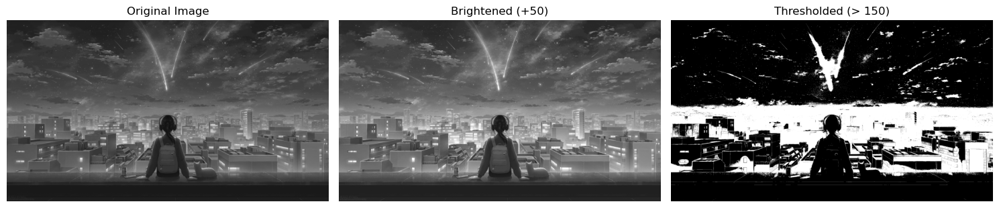

In [9]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title(f"Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(brightened, cmap='gray')
plt.title(f"Brightened (+{brightness_increase})")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(final_result, cmap='gray')
plt.title(f"Thresholded (> {threshold_val})")
plt.axis('off')

plt.tight_layout()
plt.show()

---

Display histograms of original and contrast-stretched images. Discuss the difference.

In [12]:
min_val, max_val = np.min(img), np.max(img)

if max_val > min_val:
    stretched = ((img.astype(np.float32) - min_val) * 255.0) / (max_val - min_val)
    stretched = np.clip(stretched, 0, 255).astype(np.uint8)

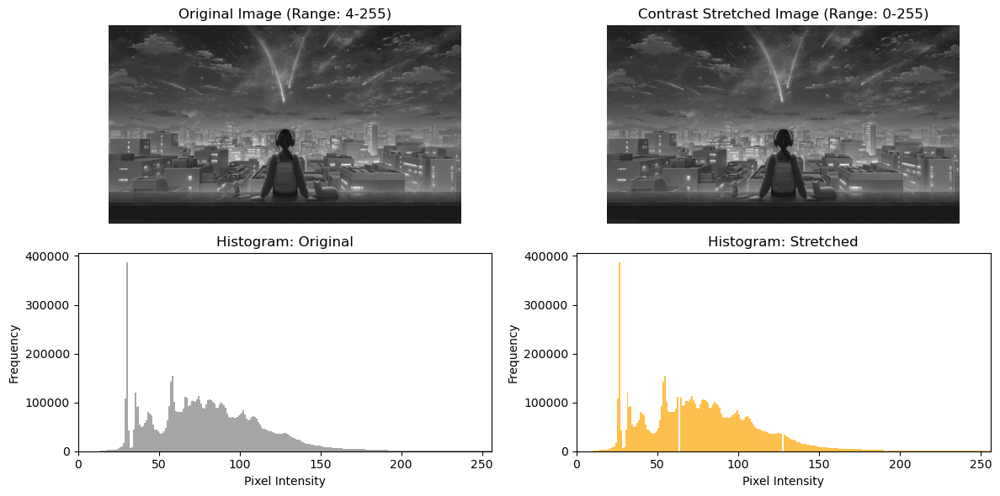

In [13]:
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title(f"Original Image (Range: {min_val}-{max_val})")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(stretched, cmap='gray')
plt.title("Contrast Stretched Image (Range: 0-255)")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray', alpha=0.7)
plt.title("Histogram: Original")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])

plt.subplot(2, 2, 4)
plt.hist(stretched.ravel(), bins=256, range=[0, 256], color='orange', alpha=0.7)
plt.title("Histogram: Stretched")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

---

Observe the output of log transformation: What happens to the dark regions?

In [15]:
img = cv2.imread('1322308.jpeg', 0)

In [18]:
img_float = img.astype(np.float32)
max_val = np.max(img_float)

In [19]:
c = 255.0 / np.log(1 + max_val)
log_transformed = c * np.log(1 + img_float)
log_transformed = np.clip(log_transformed, 0, 255).astype(np.uint8)

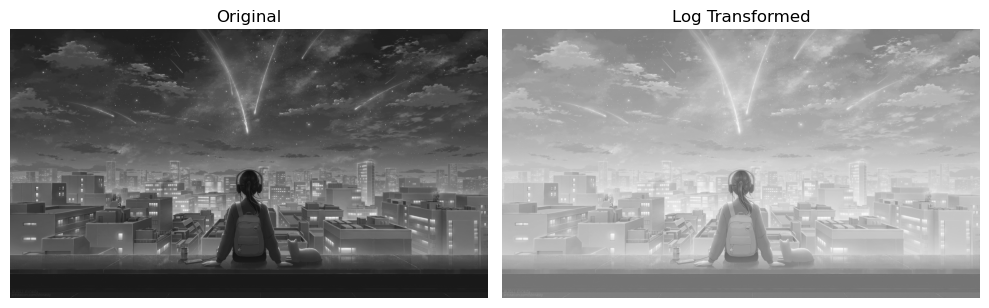

In [20]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(log_transformed, cmap='gray')
plt.title('Log Transformed')
plt.axis('off')

plt.tight_layout()
plt.show()

---

Compare the image output for gamma values <1 and >1. What differences do you see?

In [28]:
original = cv2.imread('aot.png')
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

In [29]:
def adjust_gamma(image, gamma):
    img_normalized = image.astype(np.float32) / 255.0
    img_corrected = np.power(img_normalized, 1.0 / gamma)
    return np.clip(img_corrected * 255, 0, 255).astype(np.uint8)

In [30]:
gamma_low = 0.5

img_bright = adjust_gamma(original_rgb, gamma_low)

In [31]:
gamma_high = 2.2
img_dark = adjust_gamma(original_rgb, gamma_high)

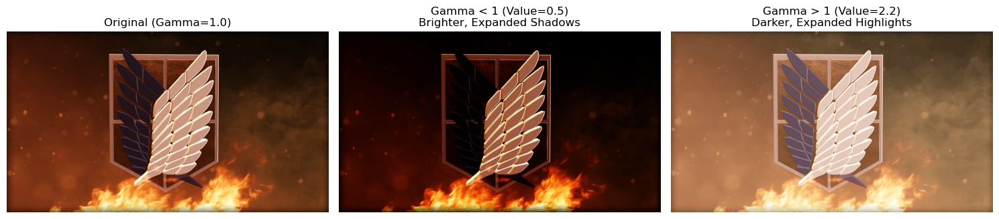

In [32]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title(f"Original (Gamma=1.0)")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_bright)
plt.title(f"Gamma < 1 (Value={gamma_low})\nBrighter, Expanded Shadows")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_dark)
plt.title(f"Gamma > 1 (Value={gamma_high})\nDarker, Expanded Highlights")
plt.axis('off')

plt.tight_layout()
plt.show()